## 1. Import Necessary libraries

In [9]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings("ignore")

## 2. Import Dataset

In [2]:
cars_data = pd.read_csv(filepath_or_buffer = "Cars.csv")
cars_data

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149
...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947
77,238,19.197888,115,150.576579,37.923113
78,263,34.000000,50,151.598513,15.769625
79,295,19.833733,119,167.944460,39.423099


## 3. Data Understanding

### 3.1 perform Initial Investigation on the data

In [3]:
cars_data.shape

(81, 5)

In [4]:
cars_data.isna().sum()

HP     0
MPG    0
VOL    0
SP     0
WT     0
dtype: int64

In [5]:
cars_data.dtypes

HP       int64
MPG    float64
VOL      int64
SP     float64
WT     float64
dtype: object

In [6]:
cars_data.describe()

,HP,MPG,VOL,SP,WT
count,81.000000,81.000000,81.000000,81.000000,81.000000
mean,117.469136,34.422076,98.765432,121.540272,32.412577
std,57.113502,9.131445,22.301497,14.181432,7.492813
min,49.000000,12.101263,50.000000,99.564907,15.712859
25%,84.000000,27.856252,89.000000,113.829145,29.591768
50%,100.000000,35.152727,101.000000,118.208698,32.734518
75%,140.000000,39.531633,113.000000,126.404312,37.392524
max,322.000000,53.700681,160.000000,169.598513,52.997752


## Now, let's check for the Assumptions

## Test 1: Linearity Test

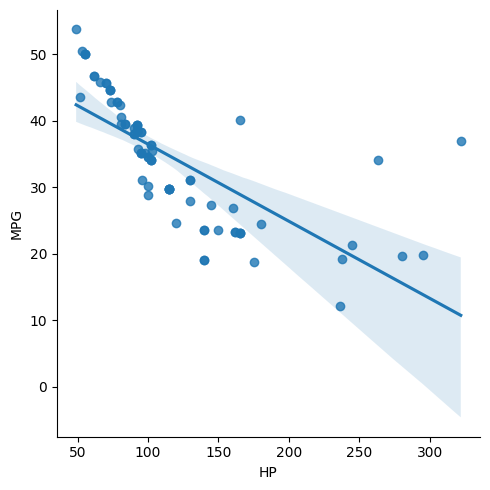

In [7]:
sns.lmplot(data = cars_data, x="HP", y="MPG",)

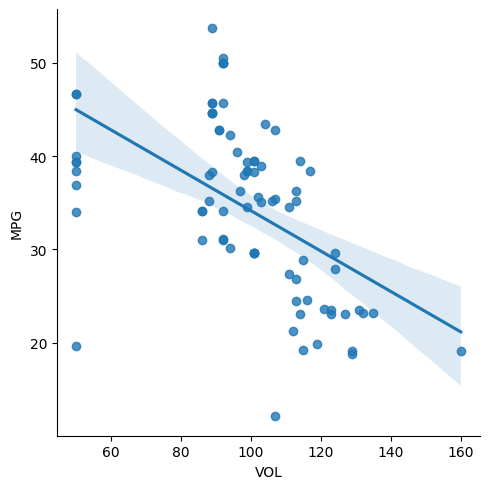

In [8]:
sns.lmplot(data = cars_data, x="VOL", y="MPG",)

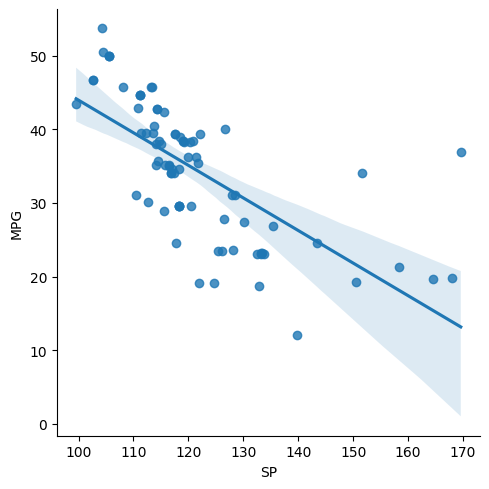

In [9]:
sns.lmplot(data = cars_data, x="SP", y="MPG",)

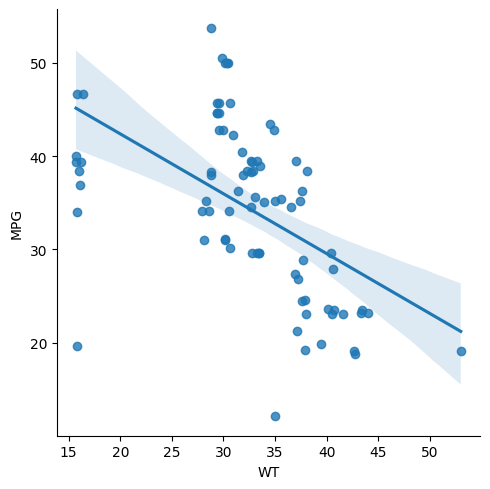

In [10]:
sns.lmplot(data = cars_data, x="WT", y="MPG",)

#### Test 1 Linearity Failed.

## Test 2: Normality Test

(array([15., 35.,  9.,  6.,  9.,  0.,  2.,  2.,  1.,  2.]),
 array([ 49. ,  76.3, 103.6, 130.9, 158.2, 185.5, 212.8, 240.1, 267.4,
        294.7, 322. ]),
 <BarContainer object of 10 artists>)

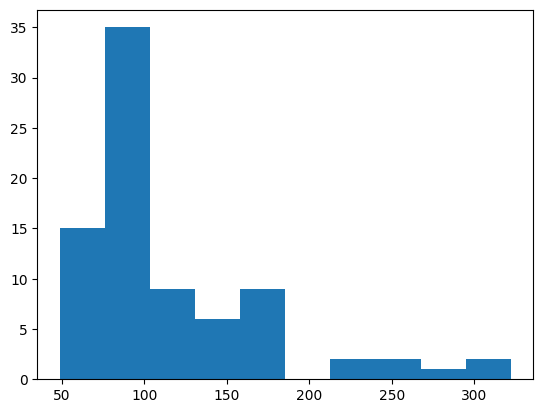

In [11]:
plt.hist(cars_data["HP"])

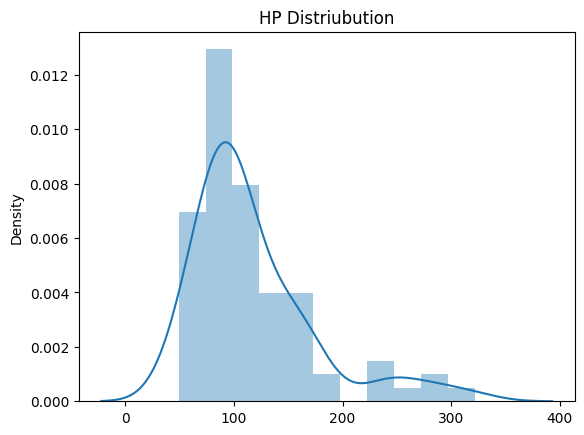

In [12]:
sns.distplot(x=cars_data["HP"])
plt.title("HP Distriubution")
plt.show()

(array([ 8., 12., 32., 10., 10.,  2.,  1.,  2.,  1.,  3.]),
 array([ 99.56490661, 106.56826723, 113.57162785, 120.57498847,
        127.57834909, 134.58170971, 141.58507032, 148.58843094,
        155.59179156, 162.59515218, 169.5985128 ]),
 <BarContainer object of 10 artists>)

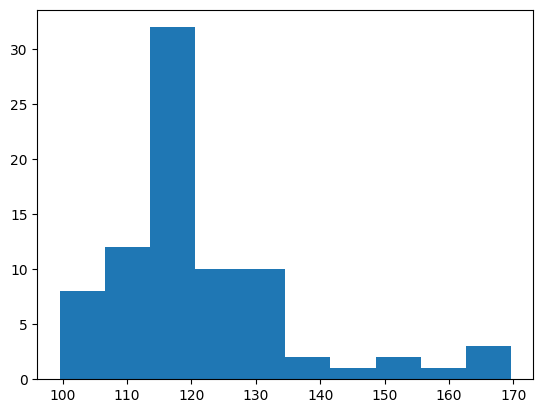

In [13]:
plt.hist(cars_data["SP"])

(array([ 9.,  0.,  0., 22., 20., 15.,  8.,  6.,  0.,  1.]),
 array([ 50.,  61.,  72.,  83.,  94., 105., 116., 127., 138., 149., 160.]),
 <BarContainer object of 10 artists>)

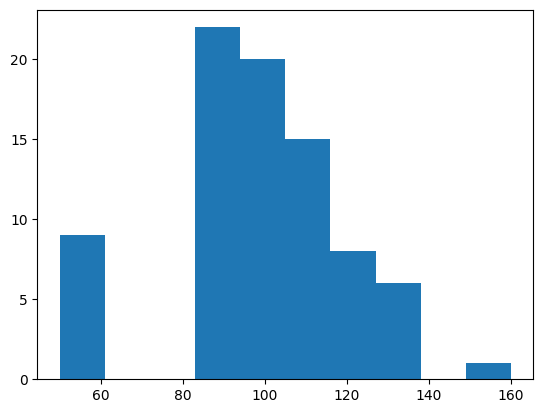

In [14]:
plt.hist(cars_data["VOL"])

(array([ 9.,  0.,  0., 22., 19., 18.,  7.,  5.,  0.,  1.]),
 array([15.71285853, 19.44134791, 23.1698373 , 26.89832668, 30.62681606,
        34.35530544, 38.08379483, 41.81228421, 45.54077359, 49.26926298,
        52.99775236]),
 <BarContainer object of 10 artists>)

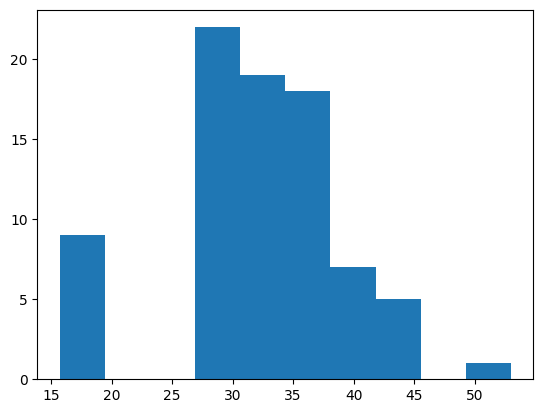

In [15]:
plt.hist(cars_data["WT"])

### Test 2 Normality also Failed

### Test 3 - Multicollinearity Test

In [16]:
corr_matrix = cars_data.corr()
corr_matrix

,HP,MPG,VOL,SP,WT
HP,1.000000,-0.725038,0.077459,0.973848,0.076513
MPG,-0.725038,1.000000,-0.529057,-0.687125,-0.526759
VOL,0.077459,-0.529057,1.000000,0.102170,0.999203
SP,0.973848,-0.687125,0.102170,1.000000,0.102439
WT,0.076513,-0.526759,0.999203,0.102439,1.000000


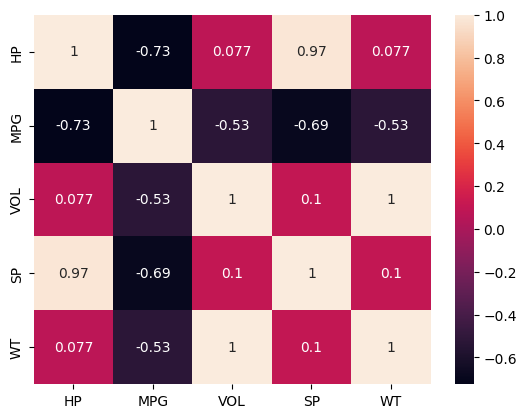

In [17]:
sns.heatmap(data = corr_matrix,annot=True)
plt.show()

### Test 3 - There is Multicollinearity in the Data

### Test 4 - AutoRegression Passed

## 4. Data Preparation

In [18]:
cars_data

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149
...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947
77,238,19.197888,115,150.576579,37.923113
78,263,34.000000,50,151.598513,15.769625
79,295,19.833733,119,167.944460,39.423099


In [7]:
X = cars_data[["HP","VOL","SP","WT"]]
X

,HP,VOL,SP,WT
0,49,89,104.185353,28.762059
1,55,92,105.461264,30.466833
2,55,92,105.461264,30.193597
3,70,92,113.461264,30.632114
4,53,92,104.461264,29.889149
...,...,...,...,...
76,322,50,169.598513,16.132947
77,238,115,150.576579,37.923113
78,263,50,151.598513,15.769625
79,295,119,167.944460,39.423099


In [8]:
y = cars_data["MPG"]
y

0     53.700681
1     50.013401
2     50.013401
3     45.696322
4     50.504232
        ...    
76    36.900000
77    19.197888
78    34.000000
79    19.833733
80    12.101263
Name: MPG, Length: 81, dtype: float64

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, shuffle=True, random_state=26)

### There is nothing to prepare because all features are numeric.

## 5. Model Building

In [11]:
linear_model  = LinearRegression()

## 6. Model Training

In [12]:
linear_model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [13]:
linear_model.intercept_

np.float64(33.54861498457865)

In [14]:
linear_model.coef_

array([-0.19540501, -0.41303294,  0.37130982,  0.60788732])

## 7.Model Testing

### 7.1 Train Data

In [17]:
y_train_pred = linear_model.predict(X_train)
y_train_pred 

array([35.47490662, 23.76067625, 42.62138847, 42.48151289, 40.82728712,
       18.50697666, 48.82241499, 39.45845048, 41.66710956, 43.12562605,
       39.97594643, 28.53017985, 34.85918675, 22.75716215, 47.22370255,
       41.65793357, 37.79651854, 33.60833016, 34.24055464, 26.5014031 ,
       28.8945446 , 21.40959398, 41.90207505, 43.38297303, 34.26058784,
       27.38162209, 18.63129834, 35.8254456 , 23.16268567, 38.36346059,
       37.58885171, 36.07807119, 20.77127965, 37.78447929, 33.18147595,
       33.47291887, 30.13984091, 41.14189643, 35.6199304 , 39.96686558,
       28.91924702, 13.07744648, 41.38116701, 36.13236448, 38.86599172,
       35.71756905, 38.91021416, 39.68890885, 37.79002962, 41.80454698,
       34.70436344, 37.27066236, 29.12578876, 16.40759645, 28.53862119,
       48.42939053, 36.43055871, 24.60635946, 37.15652501, 37.21405961,
       37.18292219, 42.38525185, 25.26432861, 27.81522903])

### 7.2 Test Data

In [16]:
y_test_pred = linear_model.predict(X_test)
y_test_pred 

array([35.22397441, 26.24865089, 37.31502066, 24.06739099, 42.31541593,
       42.1498461 , 38.55571406, 37.20609371, 36.15265208, 26.67345745,
       22.42725035, 38.45394185, 33.621558  , 38.23217695, 48.51134357,
       32.31882789, 48.16156336])

## 8. Model Evaluation

In [18]:
error = y_train - y_train_pred
error

41   -0.322180
67   -0.657505
3     3.074934
1     7.531888
9     1.471791
        ...   
65    2.835940
48   -6.168791
6     7.628149
62   -1.748412
53   -3.327862
Name: MPG, Length: 64, dtype: float64

In [19]:
error.mean()

np.float64(-6.050715484207103e-15)

In [20]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score

In [21]:
mean_absolute_error(y_train, y_train_pred) # from same unit MPG it will varry mean 

3.177427190791175

In [22]:
mean_squared_error(y_train, y_train_pred) # squared output unit

18.53269622227159

In [23]:
root_mean_squared_error(y_train, y_train_pred) #normalise the units

4.304961814264046

In [24]:
r2_score(y_train, y_train_pred)

0.7739411655243718

### To see Adjusted R2 Score, we are using OLS technique from StatsModles Formula

In [25]:
import statsmodels.formula.api as smf

In [26]:
linear_stats_model = smf.ols(formula = "MPG~HP+VOL+SP+WT", data =cars_data).fit()

In [27]:
print("R2 Score:",linear_stats_model.rsquared.round(4),"\nAdjusted R2 Score", linear_stats_model.rsquared_adj.round(4))

R2 Score: 0.7705 
Adjusted R2 Score 0.7585


In [36]:
cars_data["error"] = error
cars_data

,HP,MPG,VOL,SP,WT,error
0,49,53.700681,89,104.185353,28.762059,10.258747
1,55,50.013401,92,105.461264,30.466833,7.624608
2,55,50.013401,92,105.461264,30.193597,7.734060
3,70,45.696322,92,113.461264,30.632114,3.157963
4,53,50.504232,92,104.461264,29.889149,8.331584
...,...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947,15.617904
77,238,19.197888,115,150.576579,37.923113,1.298838
78,263,34.000000,50,151.598513,15.769625,7.863547
79,295,19.833733,119,167.944460,39.423099,7.517122


In [37]:
del cars_data["error"]

In [38]:
cars_data

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149
...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947
77,238,19.197888,115,150.576579,37.923113
78,263,34.000000,50,151.598513,15.769625
79,295,19.833733,119,167.944460,39.423099


### Let's now perform Test 5: Homoscedasticity Test

ValueError: x and y must be the same size

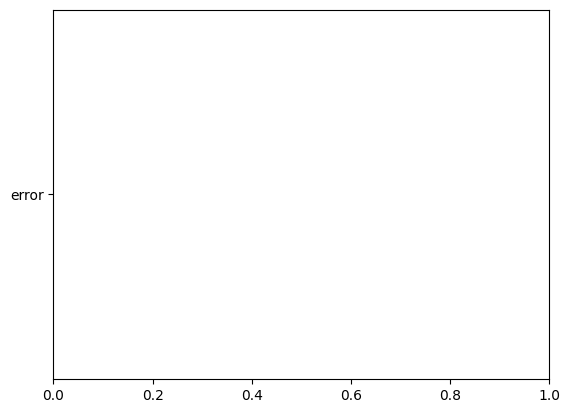

In [39]:
plt.scatter(data=cars_data, x = "HP", y = "error")

In [ ]:
sns.scatterplot( data=cars_data,x = "WT", y = error)
plt.show()

### Test 5 Homoscedasticity Test also Failed

## Test 6: Zero Residual Mean Test

In [ ]:
sns.scatterplot(x = cars_data["MPG"], y = y_pred)
plt.show()

### Test 6: Zero Residual Mean Test is also Failed

## 9. Model Deployment

In [ ]:
from pickle import dump

In [ ]:
dump(obj = linear_model,file = open(file = "linear_intelligence_file.pkl", mode='wb'))

In [ ]:
from pickle import load

In [ ]:
linear_intel_pkl = load(file = open(file = "linear_intelligence_file.pkl", mode='rb'))
linear_intel_pkl

In [ ]:
linear_intel_pkl.predict(X)

## THE END!!

## Self Task & Evaluation

split the data into Train  Test and compare the evaluation metrics